<a href="https://colab.research.google.com/github/byuruth/Econ484/blob/main/examples/07%20Classification%20(ROC).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import necessary libraries
!pip install mglearn
!git clone https://github.com/byuruth/Econ484.git
%cd /content/Econ484/examples
from preamble import *
%cd ../data

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.4/581.4 kB 6.7 MB/s eta 0:00:00
Cloning into 'Econ484'...
remote: Enumerating objects: 253, done.
remote: Counting objects: 100% (76/76), done.
remote: Compressing objects: 100% (68/68), done.
remote: Total 253 (delta 52), reused 8 (delta 8), pack-reused 177 (from 1)
Receiving objects: 100% (253/253), 11.98 MiB | 19.02 MiB/s, done.
Resolving deltas: 100% (87/87), done.
/content/Econ484/examples
/content/Econ484/data


# Import some useful packages

In [5]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

# Load data

In [2]:
mortgagedata=pd.read_csv('mortgage.csv')
print(mortgagedata.head())
print("Shape: {}".format(str(mortgagedata.shape)))

   deny  p_irat  black  hse_inc  ...  probunmp  condo  ltv_med  ltv_high
0     0    0.22      0     0.21  ...       3.2      0        0         0
1     0    0.26      0     0.22  ...       3.9      0        1         0
2     1    0.46      0     0.27  ...       5.3      0        1         0
3     0    0.49      0     0.27  ...       3.2      0        0         0
4     0    0.26      0     0.26  ...       4.3      0        0         0

[5 rows x 16 columns]
Shape: (2380, 16)


# Define sets of variables

In [3]:
y = mortgagedata.loc[:,'deny']
X = mortgagedata.drop(['deny','black'],axis=1)
print('our y vector is:\n',y.head)
print('our X matrix is:\n',X.head)

our y vector is:
 <bound method NDFrame.head of 0       0
1       0
2       1
3       0
4       0
       ..
2375    0
2376    1
2377    0
2378    0
2379    0
Name: deny, Length: 2380, dtype: int64>
our X matrix is:
 <bound method NDFrame.head of       p_irat  hse_inc  loan_val  ccred  ...  probunmp  condo  ltv_med  \
0       0.22     0.21      0.64      1  ...       3.2      0        0   
1       0.26     0.22      0.95      6  ...       3.9      0        1   
2       0.46     0.27      0.84      5  ...       5.3      0        1   
3       0.49     0.27      0.20      1  ...       3.2      0        0   
4       0.26     0.26      0.37      1  ...       4.3      0        0   
...      ...      ...       ...    ...  ...       ...    ...      ...   
2375    0.28     0.24      0.44      1  ...       3.2      1        0   
2376    0.32     0.25      0.90      1  ...       5.3      1        1   
2377    0.38     0.30      0.90      1  ...       3.1      0        1   
2378    0.32     0.29   

# Divide into test and training

In [6]:
# do on your own
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
n_test=len(y_test)
n_test

595

## Cheat

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
n_test=len(y_test)
n_test

595

# Fit logit on training set

In [8]:
logit = LogisticRegression(penalty=None).fit(X_train, y_train)
print("logit.coef_:", logit.coef_)
print("logit.intercept_:", logit.intercept_)

logit.coef_: [[ 4.837 -0.526  0.518  0.285  0.185  1.471  4.261  0.562  0.392 -0.921
   0.013  0.158  0.355  1.441]]
logit.intercept_: [-5.013]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Apply predicted probabilities to test set observations

In [9]:
phat_test=logit.predict_proba(X_test)
# the above gives two columns, one for Pr(y=0|x) and the second for Pr(y=1|x). We just need the second
phat_test=phat_test[:,1]
phat_test

array([0.319, 0.103, 0.131, 0.164, 0.048, 0.018, 0.137, 0.472, 0.027,
       0.061, 0.595, 0.112, 0.061, 0.187, 0.158, 0.026, 0.067, 0.114,
       0.034, 0.015, 0.04 , 0.05 , 0.135, 0.046, 0.261, 0.068, 0.047,
       0.926, 0.559, 0.017, 0.087, 0.071, 0.063, 0.064, 0.024, 0.081,
       0.053, 0.233, 0.365, 0.065, 0.039, 0.049, 0.765, 0.152, 0.025,
       0.044, 0.089, 0.323, 0.044, 0.063, 0.026, 0.21 , 0.096, 0.063,
       0.042, 0.027, 0.041, 0.043, 0.142, 0.43 , 0.058, 0.165, 0.06 ,
       0.047, 0.022, 0.038, 0.888, 0.014, 0.061, 0.03 , 0.041, 0.168,
       0.061, 0.037, 0.104, 0.033, 0.649, 0.048, 0.019, 0.06 , 0.072,
       0.251, 0.299, 0.092, 0.016, 0.022, 0.155, 0.038, 0.036, 0.034,
       0.034, 0.092, 0.049, 0.103, 0.042, 0.06 , 0.157, 0.049, 0.221,
       0.031, 0.057, 0.319, 0.03 , 0.177, 0.056, 0.017, 0.098, 0.024,
       0.073, 0.052, 0.059, 0.029, 0.615, 0.03 , 0.055, 0.117, 0.032,
       0.517, 0.063, 0.062, 0.041, 0.958, 0.066, 0.058, 0.04 , 0.071,
       0.152, 0.099,

#### Now make classifications for a range of thresholds, $\tau$
For each value of $\tau$, calculate the false positive rate and true positive rate

In [10]:
tpr=[0]*100
fpr=[0]*100
for i in range(100):
     tau=i/100
     yhat_test=phat_test>=tau
     tp=sum(yhat_test*y_test)
     p=sum(y_test)
     tpr[i]=tp/p
     n=sum(1-y_test)
     fp=sum(yhat_test*(1-y_test))
     fpr[i]=fp/n
     # on your own: calculate false negative rate:



#### Now plot true positive rate vs false positive rate

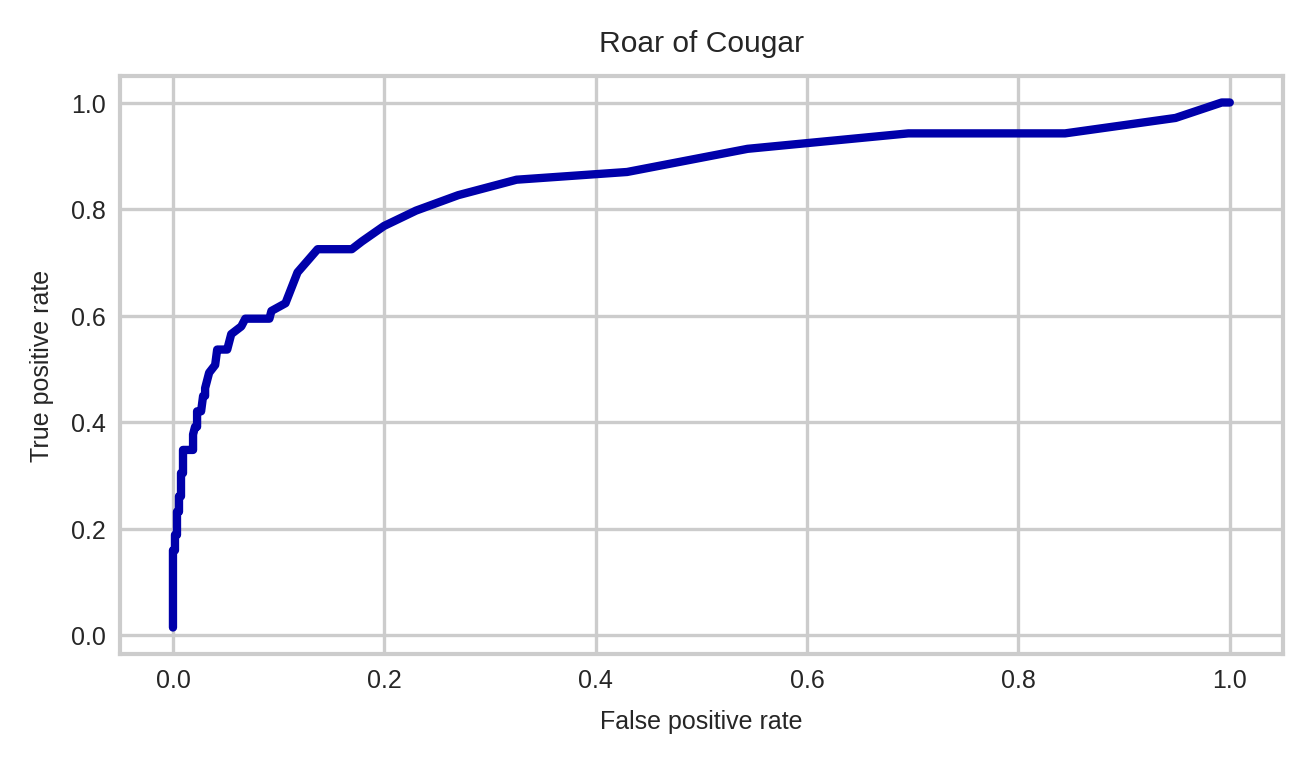

In [11]:
fig = plt.figure()
ax = plt.axes()
ax.plot(fpr,tpr);
plt.title("Roar of Cougar")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate");

#### Calculate Area Under Curve (AUC)

In [ ]:
dfpr=np.array(fpr[0:99])-np.array(fpr[1:100])
AUC=sum(np.array(tpr[0:99])*dfpr)
print(AUC)
from sklearn import metrics
metrics.auc(fpr,tpr)

To do on your own: repeat, but standardizing the x-variables and using Ridge to penalize the logit coefficients. Any improvement to AUC?

In [ ]:
# standardize using the training observations, but apply the standardization to the test observations


In [ ]:
# estimate logit model



In [ ]:
# get predicted probabilities from test observations


In [ ]:
# calculate TPR and FPR for range of probability thresholds



In [ ]:
# calculate AUC


In [ ]:
# On your own: instead of ROC Curve, plot Overall Accuracy Rate vs. Probability threshold
